# Project 4A: Image Warping and Mosaicing

In [25]:
import json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.ndimage import gaussian_filter

DATA, OUT = Path("data"), Path("out")
POINTS = DATA / "points"
OUT.mkdir(exist_ok=True); POINTS.mkdir(parents=True, exist_ok=True)
MAX_SIDE = 1200  # downscale photos so warping stays fast


def load_image(path, max_side=MAX_SIDE):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = max_side / max(img.size)
    if s < 1:
        img = img.resize((round(img.width * s), round(img.height * s)), Image.LANCZOS)
    return np.asarray(img, dtype=np.float64) / 255.0


def save_image(img, name):
    Image.fromarray((np.clip(img, 0, 1) * 255).round().astype(np.uint8)).save(OUT / name)


def show(imgs, titles=None, size=5, save=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size), squeeze=False)
    for i, (ax, im) in enumerate(zip(axes[0], imgs)):
        ax.imshow(np.clip(im, 0, 1), cmap="gray"); ax.axis("off")
        if titles: ax.set_title(titles[i])
    plt.tight_layout()
    if save: fig.savefig(OUT / save, dpi=150, bbox_inches="tight")
    plt.show()

## A.1 Shoot the Pictures

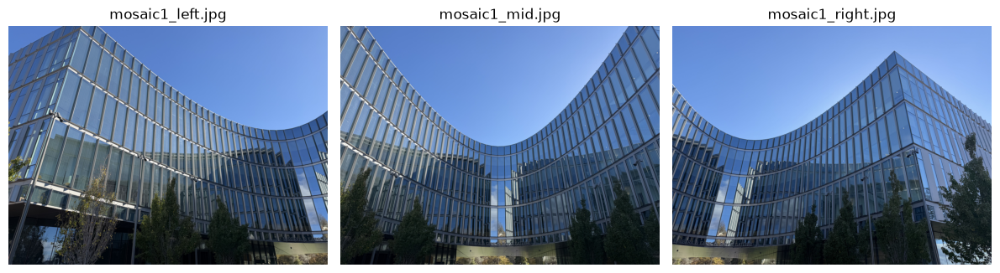

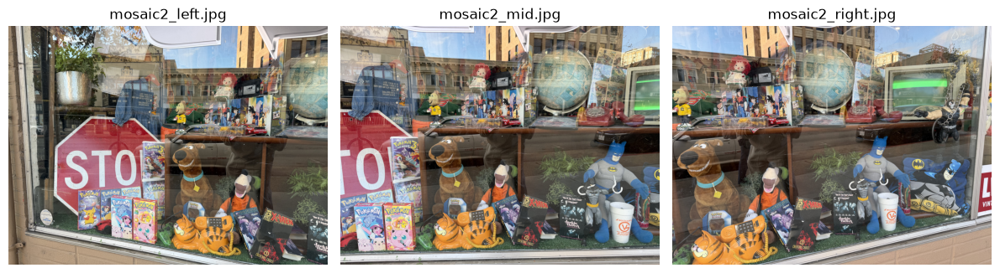

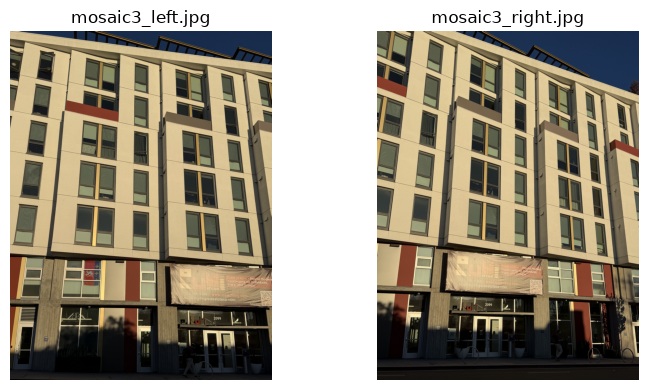

In [35]:
SETS = {
    "mosaic1": ["data/mosaic1_left.jpg", "data/mosaic1_mid.jpg", "data/mosaic1_right.jpg"],
    "mosaic2": ["data/mosaic2_left.jpg", "data/mosaic2_mid.jpg", "data/mosaic2_right.jpg"],
    "mosaic3": ["data/mosaic3_left.jpg", "data/mosaic3_right.jpg"],
}
RECT = {  # images with a known rectangular object, plus its width / height ratio
    "rect1": ("data/rect1.jpg", 1.746),
    "rect2": ("data/rect2.jpg", 1.423),
}

images = {name: [load_image(p) for p in paths] for name, paths in SETS.items()}
for name, ims in images.items():
    show(ims, [Path(p).name for p in SETS[name]], size=4, save=f"{name}_sources.jpg")

## A.2 Recover Homographies

### Selecting correspondences
`select_points` opens both images in a native window (`%matplotlib osx`) and asks you to click the
same feature alternately in the left and right image. The clicks are cached in `data/points/*.json`,
so later runs reload them without a window (pass `redo=True` to click again).
Pick **more than 4** well-spread points (corners of windows, signs, etc.) in the overlap region.

> If `%matplotlib osx` doesn't work in your editor, `pip install pyqt6` and use `%matplotlib qt`.

In [26]:
def pts_path(name, i, ref):
    return POINTS / f"{name}_{i}_to_{ref}.json"


def select_points(im1, im2, n, cache, redo=False):
    cache = Path(cache)
    if cache.exists() and not redo:
        d = json.loads(cache.read_text())
        return np.array(d["im1"], float), np.array(d["im2"], float)
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(im1); axes[1].imshow(im2)
    p1, p2 = [], []
    for k in range(n):
        for ax, pts, side in ((axes[0], p1, "LEFT"), (axes[1], p2, "RIGHT")):
            fig.suptitle(f"point {k + 1}/{n}: click in the {side} image")
            fig.canvas.draw()
            x, y = plt.ginput(1, timeout=0)[0]
            pts.append((float(x), float(y)))
            ax.plot(x, y, "r+", ms=14, mew=2); ax.text(x + 5, y - 5, str(k + 1), color="yellow")
    plt.close(fig)
    cache.write_text(json.dumps({"im1": p1, "im2": p2}))
    return np.array(p1), np.array(p2)


def plot_correspondences(im1, im2, p1, p2, titles=("image 1", "image 2"), save=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, im, p, t in zip(axes, (im1, im2), (p1, p2), titles):
        ax.imshow(im); ax.set_title(t); ax.axis("off")
        ax.scatter(p[:, 0], p[:, 1], s=60, facecolors="none", edgecolors="r", linewidths=2)
        for k, (x, y) in enumerate(p):
            ax.text(x + 8, y - 8, str(k + 1), color="yellow", fontsize=11, weight="bold")
    plt.tight_layout()
    if save: fig.savefig(OUT / save, dpi=150, bbox_inches="tight")
    plt.show()

Click the correspondences for every non-reference image of every set against that set's
reference (middle) image. This is the only cell that opens a window; with cached points it
just reloads them.

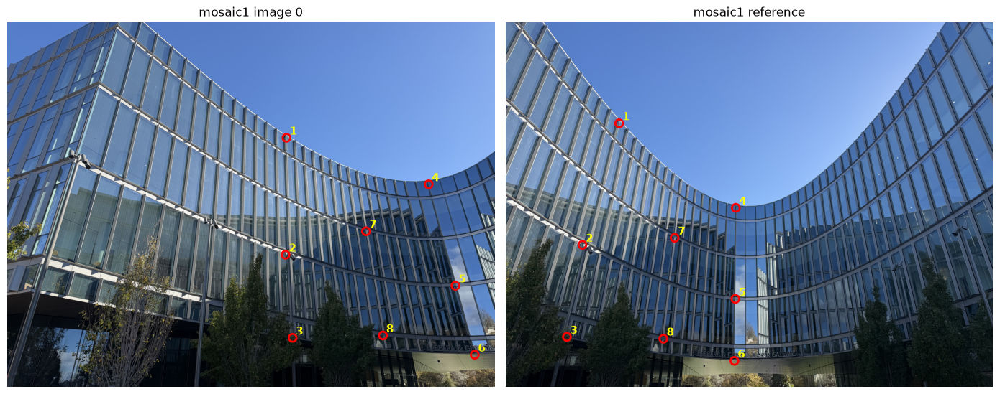

In [27]:
%matplotlib osx
N_PTS = 8
pairs = {}  # (name, i) -> (pts in image i, pts in reference image)
for name, ims in images.items():
    ref = len(ims) // 2
    for i in range(len(ims)):
        if i != ref:
            pairs[name, i] = select_points(ims[i], ims[ref], N_PTS, pts_path(name, i, ref))
%matplotlib inline

ims = images["mosaic1"]; ref = len(ims) // 2
p_src, p_ref = pairs["mosaic1", 0]
plot_correspondences(ims[0], ims[ref], p_src, p_ref, ("mosaic1 image 0", "mosaic1 reference"),
                     save="mosaic1_correspondences.jpg")

### Solving for H
For each correspondence $(x, y) \to (u, v)$, with $h_{33}=1$:

$$u = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + 1},\qquad
v = \frac{h_{21}x + h_{22}y + h_{23}}{h_{31}x + h_{32}y + 1}$$

Multiplying out gives two linear equations per point:

$$\begin{bmatrix} x & y & 1 & 0 & 0 & 0 & -ux & -uy \\ 0 & 0 & 0 & x & y & 1 & -vx & -vy \end{bmatrix}
\mathbf{h} = \begin{bmatrix} u \\ v \end{bmatrix}$$

Stacking $n > 4$ points gives an overdetermined system $A\mathbf{h} = \mathbf{b}$ ($2n \times 8$),
which is solved by least squares.

In [28]:
def apply_H(H, pts):
    p = np.c_[pts, np.ones(len(pts))] @ H.T
    return p[:, :2] / p[:, 2:3]


def build_system(im1_pts, im2_pts):
    A, b = [], []
    for (x, y), (u, v) in zip(im1_pts, im2_pts):
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y]); b.append(u)
        A.append([0, 0, 0, x, y, 1, -v * x, -v * y]); b.append(v)
    return np.array(A, float), np.array(b, float)


def computeH(im1_pts, im2_pts):
    A, b = build_system(im1_pts, im2_pts)
    h = np.linalg.lstsq(A, b, rcond=None)[0]
    return np.append(h, 1).reshape(3, 3)

In [29]:
A, b = build_system(p_src, p_ref)
H = computeH(p_src, p_ref)
with np.printoptions(precision=1, suppress=True, linewidth=150):
    print(f"A ({A.shape[0]}x{A.shape[1]}) | b:")
    print(np.c_[A, b])
with np.printoptions(precision=6, suppress=True):
    print("\nRecovered H (mosaic1 image 0 -> reference):\n", H)
err = np.linalg.norm(apply_H(H, p_src) - p_ref, axis=1)
print(f"\nreprojection error: mean {err.mean():.2f}px, max {err.max():.2f}px")

A (16x8) | b:
[[    687.2     285.        1.        0.        0.        0.  -192080.1  -79656.8     279.5]
 [      0.        0.        0.      687.2     285.        1.  -171139.5  -70972.6     249.1]
 [    684.8     573.5       1.        0.        0.        0.  -129539.3 -108473.7     189.2]
 [      0.        0.        0.      684.8     573.5       1.  -376079.2 -314921.4     549.1]
 [    702.2     778.6       1.        0.        0.        0.  -105976.6 -117496.5     150.9]
 [      0.        0.        0.      702.2     778.6       1.  -545096.4 -604349.3     776.2]
 [   1037.1     399.7       1.        0.        0.        0.  -587891.4 -226566.6     566.9]
 [      0.        0.        0.     1037.1     399.7       1.  -474577.6 -182896.8     457.6]
 [   1103.1     649.9       1.        0.        0.        0.  -624051.6 -367684.9     565.7]
 [      0.        0.        0.     1103.1     649.9       1.  -752758.7 -443517.8     682.4]
 [   1150.6     820.3       1.        0.        0.      

## A.3 Warp the Images

**Inverse warping**: transform the four corners with $H$ to get the output bounding box, then for
every output pixel compute its source location with $H^{-1}$ and sample the source image there.
Every output pixel gets a value, so there are no holes. Pixels whose source falls outside the
image get `alpha = 0`.

In [30]:
def warp_bbox(shape, H):
    h, w = shape[:2]
    c = apply_H(H, np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], float))
    x0, y0 = np.floor(c.min(0)).astype(int)
    x1, y1 = np.ceil(c.max(0)).astype(int)
    return x0, y0, x1 - x0 + 1, y1 - y0 + 1  # x0, y0, width, height


def inverse_map(H, bbox):
    x0, y0, W, Hgt = bbox
    if W * Hgt > 60e6:
        raise ValueError(f"output would be {W}x{Hgt}; the homography is too extreme")
    xs, ys = np.meshgrid(np.arange(x0, x0 + W), np.arange(y0, y0 + Hgt))
    src = apply_H(np.linalg.inv(H), np.c_[xs.ravel(), ys.ravel()])
    return src[:, 0].reshape(Hgt, W), src[:, 1].reshape(Hgt, W)


def warpImageNearestNeighbor(im, H, bbox=None):
    bbox = warp_bbox(im.shape, H) if bbox is None else bbox
    sx, sy = inverse_map(H, bbox)
    xi, yi = np.rint(sx).astype(int), np.rint(sy).astype(int)
    h, w = im.shape[:2]
    alpha = (xi >= 0) & (xi < w) & (yi >= 0) & (yi < h)
    out = np.zeros((bbox[3], bbox[2]) + im.shape[2:])
    out[alpha] = im[yi[alpha], xi[alpha]]
    return out, alpha.astype(float), bbox[:2]

In [31]:
def bilinear_sample(im, x, y):
    h, w = im.shape[:2]
    valid = (x >= 0) & (x <= w - 1) & (y >= 0) & (y <= h - 1)
    x0 = np.clip(np.floor(x).astype(int), 0, w - 2)
    y0 = np.clip(np.floor(y).astype(int), 0, h - 2)
    ax, ay = np.clip(x - x0, 0, 1), np.clip(y - y0, 0, 1)
    if im.ndim == 3:
        ax, ay = ax[..., None], ay[..., None]
    top = im[y0, x0] * (1 - ax) + im[y0, x0 + 1] * ax
    bot = im[y0 + 1, x0] * (1 - ax) + im[y0 + 1, x0 + 1] * ax
    out = top * (1 - ay) + bot * ay
    out[~valid] = 0
    return out, valid.astype(float)


def warpImageBilinear(im, H, bbox=None):
    bbox = warp_bbox(im.shape, H) if bbox is None else bbox
    sx, sy = inverse_map(H, bbox)
    out, alpha = bilinear_sample(im, sx, sy)
    return out, alpha, bbox[:2]

### Rectification
Click the 4 corners of a known rectangle in the order **top-left, top-right, bottom-right,
bottom-left**. They are mapped to an axis-aligned rectangle with the known aspect ratio
(width / height). The rectangle's width is the average length of the clicked top and bottom
edges, which keeps roughly the original resolution. Only the rectangle plus a `margin`
(fraction of its size) around it is warped, since far-away parts of the photo get stretched
enormously by a rectifying homography.

In [32]:
def click_points(im, n, cache, redo=False):
    cache = Path(cache)
    if cache.exists() and not redo:
        return np.array(json.loads(cache.read_text()), float)
    fig = plt.figure(figsize=(10, 8)); plt.imshow(im)
    plt.title(f"click {n} points: TL, TR, BR, BL")
    pts = np.array(plt.ginput(n, timeout=0), float)
    plt.close(fig)
    cache.write_text(json.dumps(pts.tolist()))
    return pts


def rectify(im, pts, aspect, warp=warpImageBilinear, margin=0.5):
    out_w = (np.linalg.norm(pts[1] - pts[0]) + np.linalg.norm(pts[2] - pts[3])) / 2
    out_h = out_w / aspect
    dst = np.array([[0, 0], [out_w - 1, 0], [out_w - 1, out_h - 1], [0, out_h - 1]])
    H = computeH(pts, dst)
    # keep the rectangle plus `margin` of its size on each side, clipped to the full warp
    fx, fy, fw, fh = warp_bbox(im.shape, H)
    x0, y0 = max(fx, int(-margin * out_w)), max(fy, int(-margin * out_h))
    x1, y1 = min(fx + fw, int((1 + margin) * out_w)), min(fy + fh, int((1 + margin) * out_h))
    bbox = (x0, y0, x1 - x0, y1 - y0)
    out, alpha, _ = warp(im, H, bbox)
    return out, alpha, H, bbox

rect1: nearest 0.07s, bilinear 0.17s


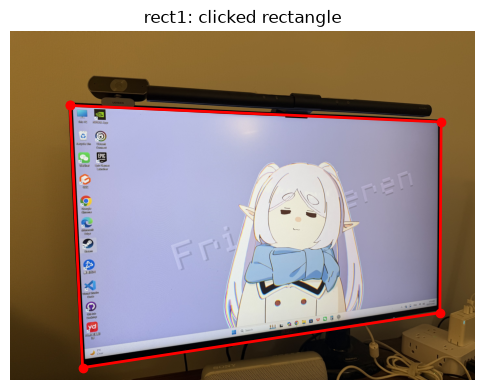

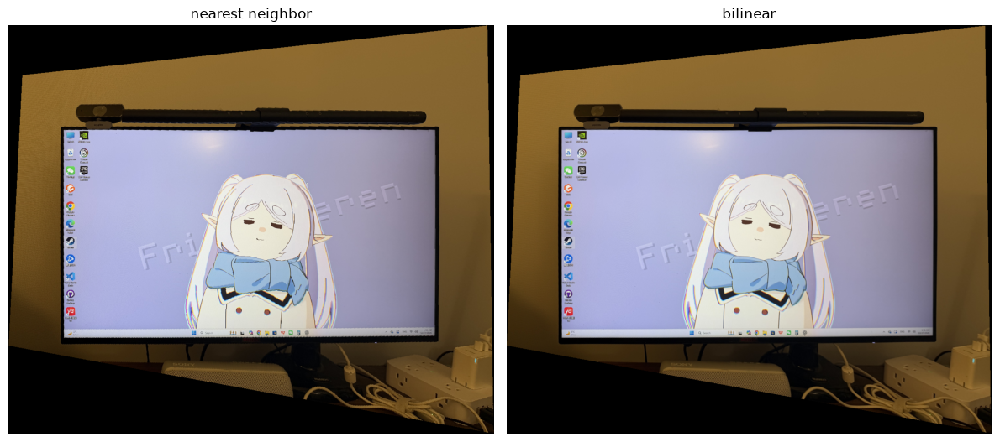

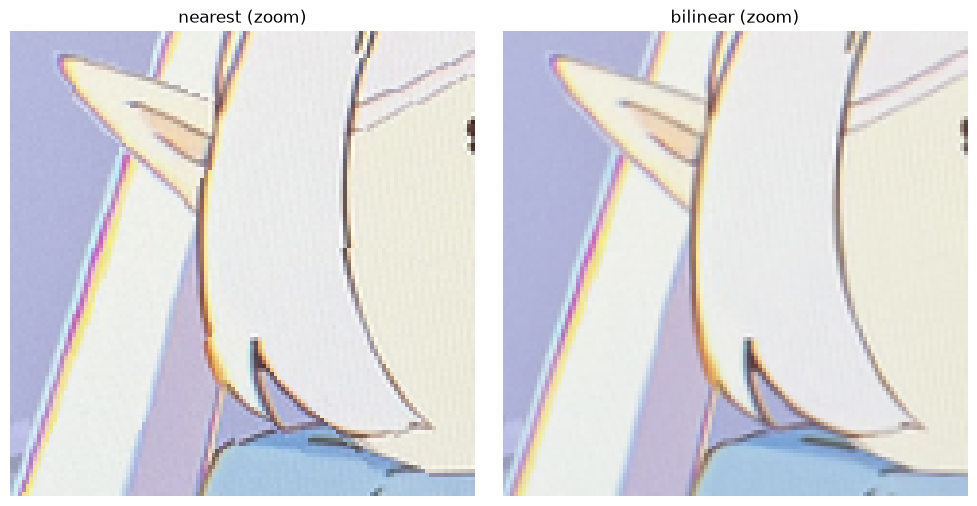

rect2: nearest 0.07s, bilinear 0.16s


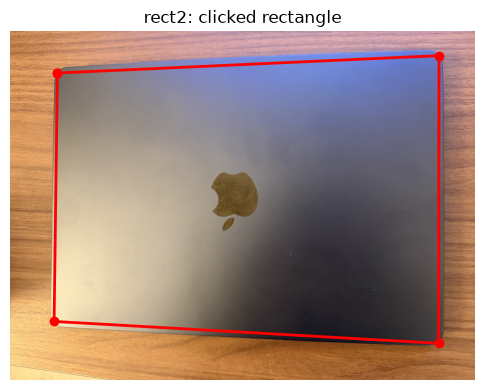

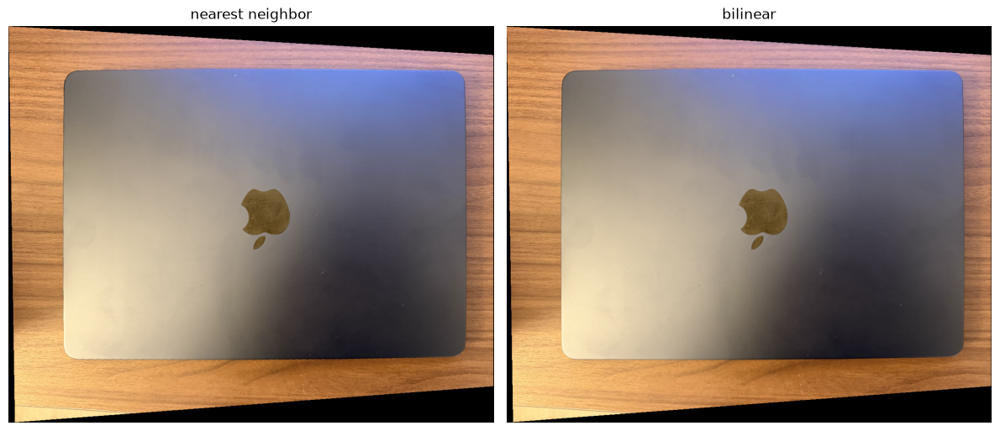

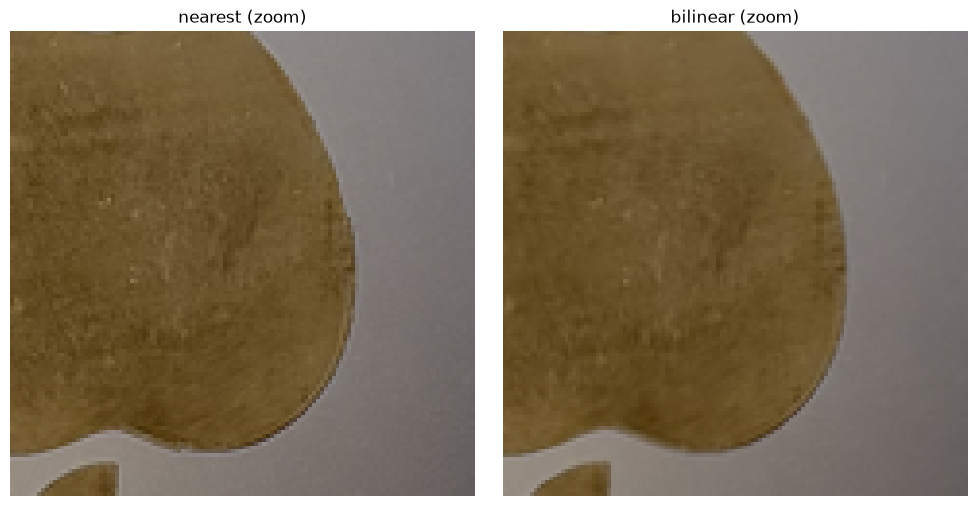

In [36]:
%matplotlib osx
rect_pts = {name: click_points(load_image(path), 4, POINTS / f"{name}.json")
            for name, (path, _) in RECT.items()}
%matplotlib inline

for name, (path, aspect) in RECT.items():
    im, pts = load_image(path), rect_pts[name]
    results = {}
    for label, warp in (("nearest", warpImageNearestNeighbor), ("bilinear", warpImageBilinear)):
        t = time.perf_counter()
        out, alpha, H, bbox = rectify(im, pts, aspect, warp)
        results[label] = (out, time.perf_counter() - t)
        save_image(out, f"{name}_{label}.jpg")
    print(f"{name}: nearest {results['nearest'][1]:.2f}s, bilinear {results['bilinear'][1]:.2f}s")

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.imshow(im); ax.plot(*np.r_[pts, pts[:1]].T, "r-o", lw=2); ax.axis("off")
    ax.set_title(f"{name}: clicked rectangle")
    fig.savefig(OUT / f"{name}_input.jpg", dpi=150, bbox_inches="tight"); plt.show()
    show([results["nearest"][0], results["bilinear"][0]], ["nearest neighbor", "bilinear"],
         size=6, save=f"{name}_compare.jpg")

    # zoom into the middle of the rectified rectangle to compare interpolation quality
    cx, cy = (apply_H(H, pts.mean(0, keepdims=True))[0] - bbox[:2]).astype(int)
    crops = [r[0][max(cy - 60, 0):cy + 60, max(cx - 60, 0):cx + 60] for r in results.values()]
    show(crops, ["nearest (zoom)", "bilinear (zoom)"], size=5, save=f"{name}_zoom.jpg")

## A.4 Blend the Images into a Mosaic

In [37]:
def feather_alpha(h, w):
    y, x = np.mgrid[0:h, 0:w]
    d = np.minimum.reduce([x + 1, w - x, y + 1, h - y]).astype(float)
    return d / d.max()


def canvas_bbox(shapes, Hs):
    boxes = np.array([warp_bbox(s, H) for s, H in zip(shapes, Hs)])
    x0, y0 = boxes[:, 0].min(), boxes[:, 1].min()
    x1, y1 = (boxes[:, 0] + boxes[:, 2]).max(), (boxes[:, 1] + boxes[:, 3]).max()
    return x0, y0, x1 - x0, y1 - y0

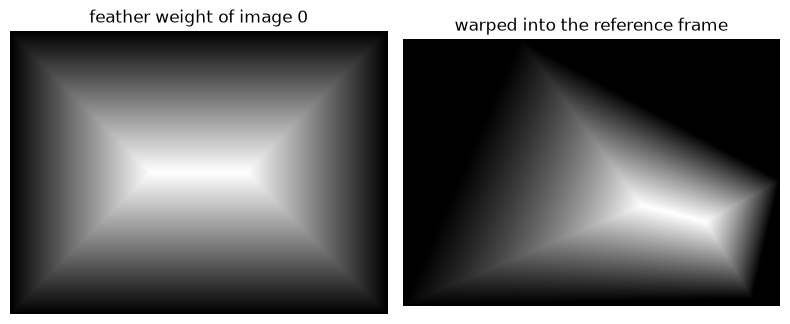

In [38]:
ims = images["mosaic1"]
f_demo = feather_alpha(*ims[0].shape[:2])
f_warp, a_warp, _ = warpImageBilinear(f_demo, computeH(*pairs["mosaic1", 0]))
show([f_demo, f_warp * a_warp], ["feather weight of image 0", "warped into the reference frame"], size=4)

In [39]:
def blend_two_band(imgs, weights, sigma=5):
    W = np.stack(weights)  # n, H, W
    lows, highs = [], []
    for im, w in zip(imgs, W):
        m = (w > 0).astype(float)
        low = gaussian_filter(im * m[..., None], (sigma, sigma, 0)) / \
              np.maximum(gaussian_filter(m, sigma), 1e-6)[..., None]
        lows.append(low * m[..., None]); highs.append((im - low) * m[..., None])
    total = W.sum(0)
    low = np.einsum("nhw,nhwc->hwc", W, np.stack(lows)) / np.maximum(total, 1e-12)[..., None]
    best = W.argmax(0)
    high = np.take_along_axis(np.stack(highs), best[None, ..., None], 0)[0]
    return np.clip(low + high, 0, 1) * (total > 0)[..., None]


def make_mosaic(imgs, Hs, weights=None, sigma=5):
    weights = weights or [feather_alpha(*im.shape[:2]) for im in imgs]
    bbox = canvas_bbox([im.shape for im in imgs], Hs)
    warped, ws = [], []
    for im, w, H in zip(imgs, weights, Hs):
        out, alpha, _ = warpImageBilinear(np.dstack([im, w]), H, bbox)
        warped.append(out[..., :3]); ws.append(out[..., 3] * alpha)
    return blend_two_band(warped, ws, sigma), warped, ws

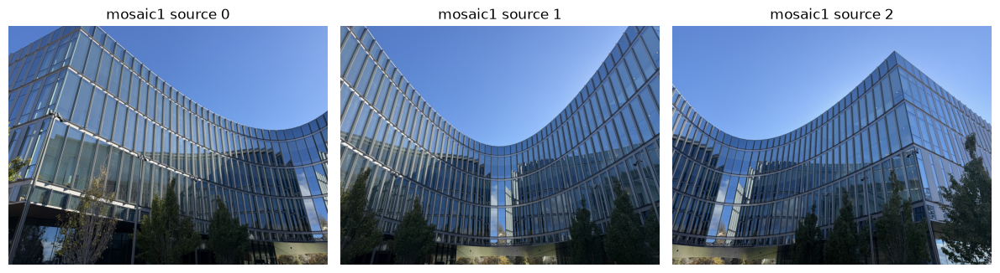

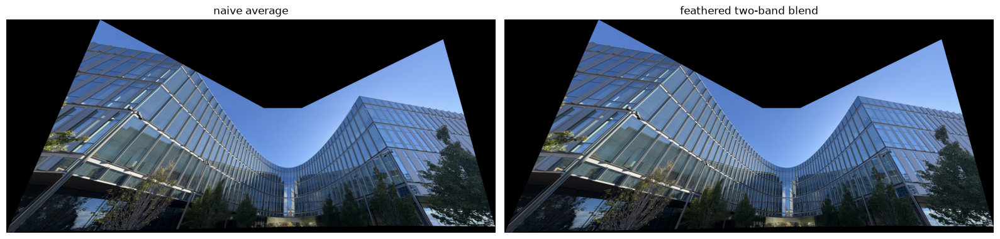

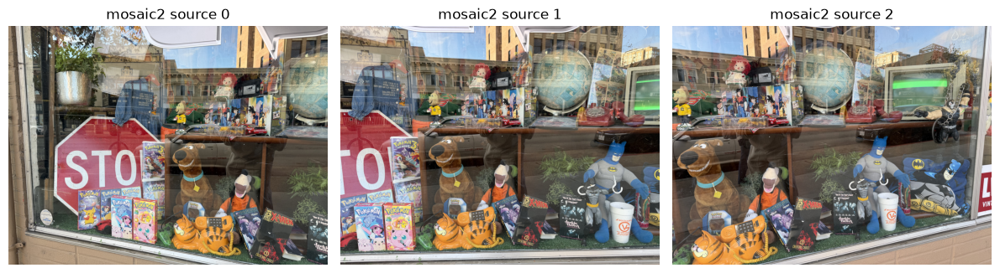

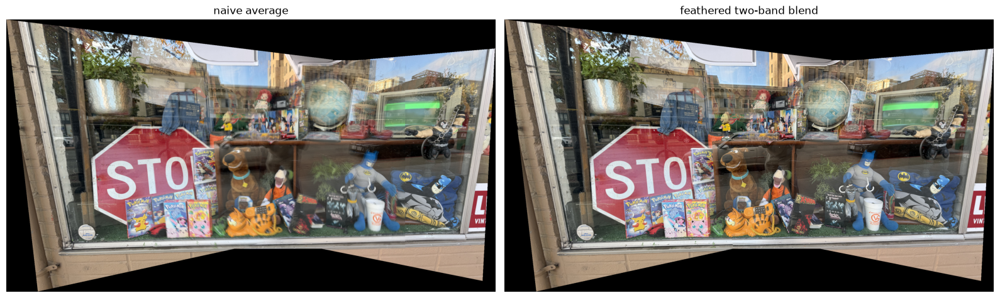

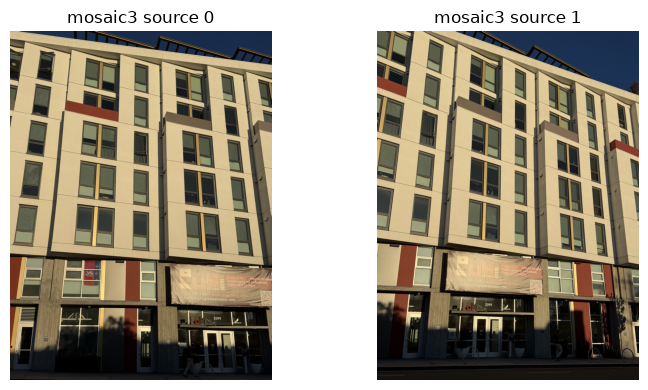

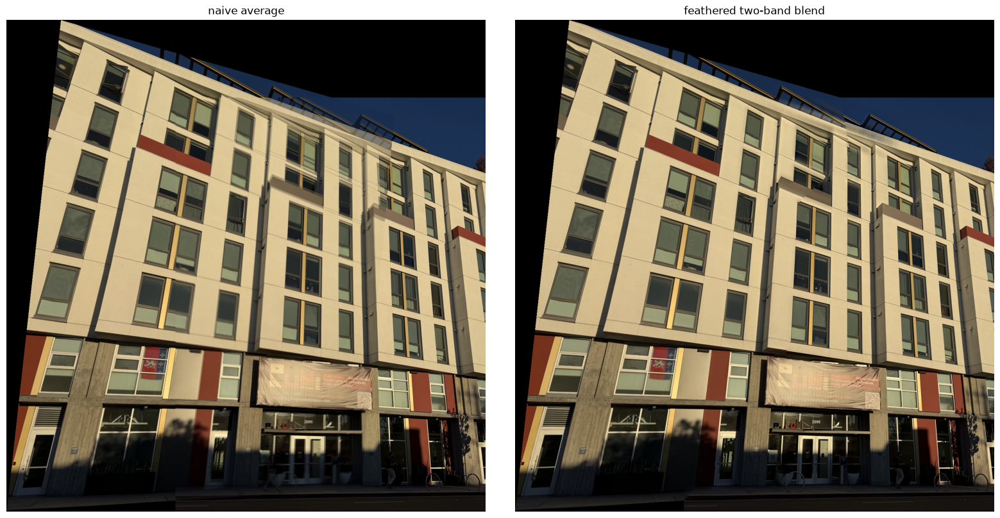

In [40]:
mosaics = {}
for name, ims in images.items():
    ref = len(ims) // 2
    Hs = [np.eye(3) if i == ref else computeH(*pairs[name, i]) for i in range(len(ims))]
    mosaic, warped, ws = make_mosaic(ims, Hs)
    mosaics[name] = (mosaic, Hs)

    # naive overlay (plain average where images overlap) for comparison
    masks = [(w > 0)[..., None] for w in ws]
    naive = sum(m * im for m, im in zip(masks, warped)) / np.maximum(sum(masks), 1)
    show(ims, [f"{name} source {i}" for i in range(len(ims))], size=4)
    show([naive, mosaic], ["naive average", "feathered two-band blend"], size=8)
    save_image(naive, f"{name}_naive.jpg"); save_image(mosaic, f"{name}_mosaic.jpg")

## A.5 Bells & Whistles: Cylindrical Mapping

In [41]:
def focal_px(path, shape):
    exif = Image.open(path).getexif().get_ifd(0x8769)
    f35 = exif.get(41989)  # FocalLengthIn35mmFilm
    h, w = shape[:2]
    return f35 * np.hypot(h, w) / 43.27 if f35 else 0.8 * max(h, w)


def cyl_bbox(shape, f, R=np.eye(3)):
    # forward-map points along the image border onto the cylinder to find its extent
    h, w = shape[:2]
    t = np.linspace(0, 1, 200)
    border = np.r_[np.c_[t * (w - 1), 0 * t], np.c_[t * (w - 1), 0 * t + h - 1],
                   np.c_[0 * t, t * (h - 1)], np.c_[0 * t + w - 1, t * (h - 1)]]
    d = np.c_[border - [(w - 1) / 2, (h - 1) / 2], np.full(len(border), f)] @ R.T
    x, y = f * np.arctan2(d[:, 0], d[:, 2]), f * d[:, 1] / np.hypot(d[:, 0], d[:, 2])
    x0, y0 = int(np.floor(x.min())), int(np.floor(y.min()))
    return x0, y0, int(np.ceil(x.max())) - x0 + 1, int(np.ceil(y.max())) - y0 + 1


def cylindrical_warp(im, f, R=np.eye(3), bbox=None):
    h, w = im.shape[:2]
    x0, y0, W, Hgt = cyl_bbox(im.shape, f, R) if bbox is None else bbox
    xs, ys = np.meshgrid(np.arange(x0, x0 + W) / f, np.arange(y0, y0 + Hgt) / f)
    d = np.stack([np.sin(xs), ys, np.cos(xs)], -1) @ R  # rows are R^T d: rays in camera i
    front = d[..., 2] > 1e-6
    z = np.where(front, d[..., 2], 1)
    out, alpha = bilinear_sample(im, f * d[..., 0] / z + (w - 1) / 2, f * d[..., 1] / z + (h - 1) / 2)
    return out, alpha * front, (x0, y0)

mosaic1: f = 832px


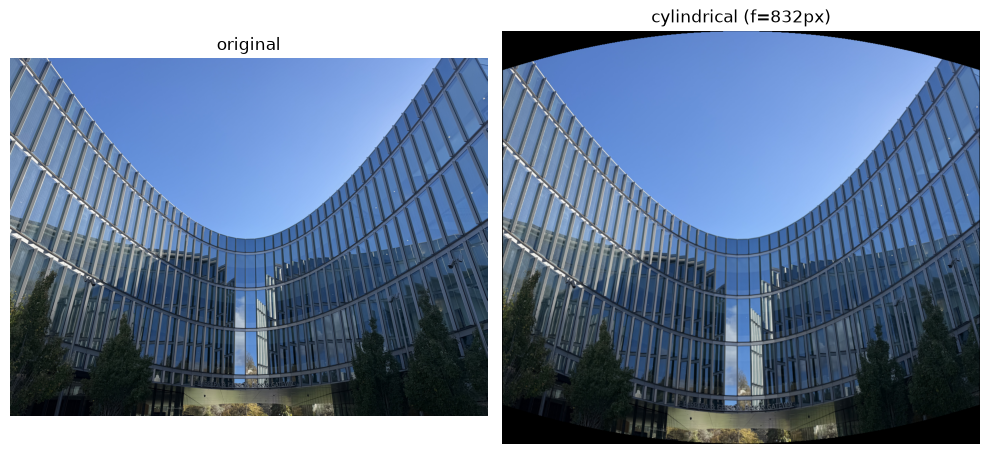

In [42]:
name = "mosaic1"
ims = images[name]
ref = len(ims) // 2
f = focal_px(SETS[name][ref], ims[ref].shape)
cyl, cyl_alpha, _ = cylindrical_warp(ims[ref], f)
print(f"{name}: f = {f:.0f}px")
show([ims[ref], cyl * cyl_alpha[..., None]], ["original", f"cylindrical (f={f:.0f}px)"], size=5)

In [43]:
def rotation_from_points(p_i, p_ref, f, shape):
    h, w = shape[:2]
    def rays(p):
        r = np.c_[p - [(w - 1) / 2, (h - 1) / 2], np.full(len(p), f)]
        return r / np.linalg.norm(r, axis=1, keepdims=True)
    a, b = rays(p_i), rays(p_ref)
    U, _, Vt = np.linalg.svd(b.T @ a)
    R = U @ np.diag([1, 1, np.linalg.det(U @ Vt)]) @ Vt
    return R, f * np.linalg.norm(a @ R.T - b, axis=1).mean()


def cylindrical_mosaic(imgs, pairs_for_set, f, sigma=5):
    ref = len(imgs) // 2
    Rs = [np.eye(3) if i == ref else rotation_from_points(*pairs_for_set[i], f, im.shape)[0]
          for i, im in enumerate(imgs)]
    boxes = np.array([cyl_bbox(im.shape, f, R) for im, R in zip(imgs, Rs)])
    x0, y0 = boxes[:, 0].min(), boxes[:, 1].min()
    bbox = (x0, y0, (boxes[:, 0] + boxes[:, 2]).max() - x0, (boxes[:, 1] + boxes[:, 3]).max() - y0)
    warped, ws = [], []
    for im, R in zip(imgs, Rs):
        out, alpha, _ = cylindrical_warp(np.dstack([im, feather_alpha(*im.shape[:2])]), f, R, bbox)
        warped.append(out[..., :3]); ws.append(out[..., 3] * alpha)
    return blend_two_band(warped, ws, sigma)

mosaic1 image 0: ray misalignment 1.60px
mosaic1 image 2: ray misalignment 4.42px


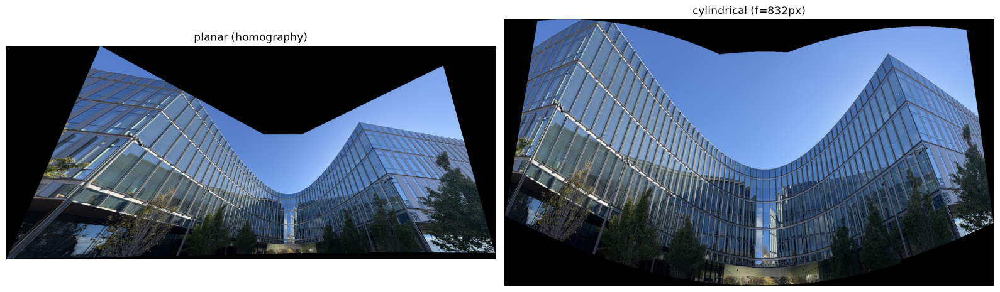

mosaic2 image 0: ray misalignment 12.38px
mosaic2 image 2: ray misalignment 14.75px


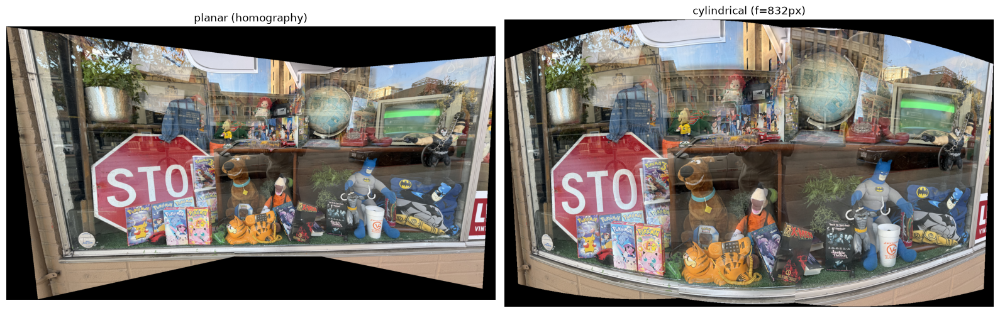

mosaic3 image 0: ray misalignment 5.37px


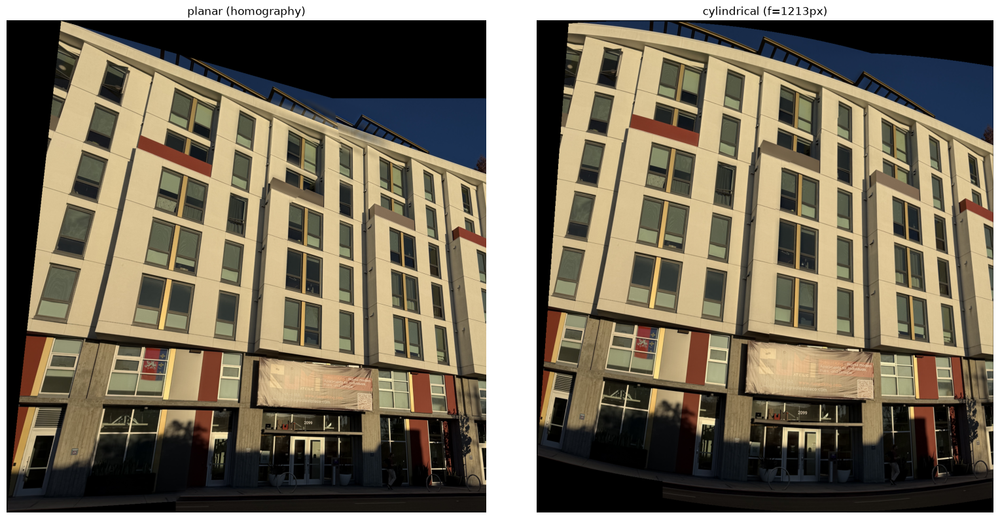

In [44]:
cyl_mosaics = {}
for name, ims in images.items():
    ref = len(ims) // 2
    f = focal_px(SETS[name][ref], ims[ref].shape)
    pairs_for_set = {i: pairs[name, i] for i in range(len(ims)) if i != ref}
    for i, (p_i, p_ref) in pairs_for_set.items():
        print(f"{name} image {i}: ray misalignment {rotation_from_points(p_i, p_ref, f, ims[i].shape)[1]:.2f}px")
    cyl_mosaics[name] = cylindrical_mosaic(ims, pairs_for_set, f)
    show([mosaics[name][0], cyl_mosaics[name]], ["planar (homography)", f"cylindrical (f={f:.0f}px)"], size=8)
    save_image(cyl_mosaics[name], f"{name}_cylindrical.jpg")

**Choosing f.** The sweep below varies $f$ around the EXIF value and plots the mean ray
misalignment of the clicked points. Too small an $f$ over-bends the image, so straight lines bow
and the overlap regions disagree. Too large an $f$ approaches the planar projection. 

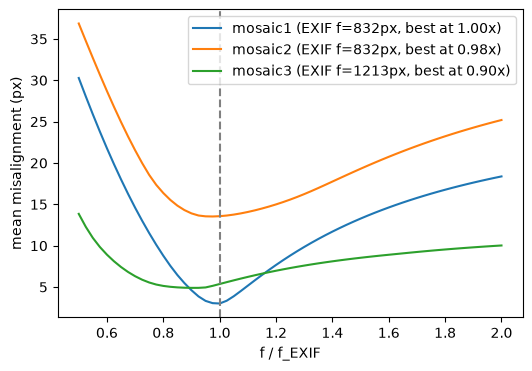

In [45]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, ims in images.items():
    ref = len(ims) // 2
    f0 = focal_px(SETS[name][ref], ims[ref].shape)
    scales = np.linspace(0.5, 2.0, 61)
    errs = [np.mean([rotation_from_points(*pairs[name, i], s * f0, ims[i].shape)[1]
                     for i in range(len(ims)) if i != ref]) for s in scales]
    ax.plot(scales, errs, label=f"{name} (EXIF f={f0:.0f}px, best at {scales[np.argmin(errs)]:.2f}x)")
ax.axvline(1, color="gray", ls="--"); ax.set_xlabel("f / f_EXIF"); ax.set_ylabel("mean misalignment (px)")
ax.legend(); fig.savefig(OUT / "focal_sweep.jpg", dpi=150, bbox_inches="tight"); plt.show()